# Momentum Trading Strategy: S&P 500

Selects S&P 500 stocks with a momentum signal, forms return views with ARIMA, and allocates with Black-Litterman. The portfolio is rebalanced quarterly in a **walk-forward** backtest: every decision on a rebalance date uses only data available on that date. All portfolios, benchmarks included, pay transaction costs.

**Pipeline**

1. Load the S&P 500 constituent snapshots
2. Load and clean the daily data, choosing the right listing when a company has two
3. Build a point-in-time universe
4. Select stocks by momentum (12-1 month return, filtered by RSI)
5. Forecast next-quarter returns with ARIMA, which become the Black-Litterman views
6. Combine the market prior and the views with Black-Litterman (Ledoit-Wolf covariance), then optimise for maximum Sharpe
7. Backtest engine: drifted weights, turnover and transaction costs
8. Walk-forward backtest over 2023
9. Walk-forward backtest over 2010–2023
10. Where the return comes from: each layer of the strategy tested on its own
11. Sensitivity to settings, costs and time period
12. Full S&P 500 universe: momentum across all ~500 members, not just the 50 largest
13. Reducing turnover: no-trade bands and partial rebalancing
14. Findings

Charts are also saved to `images/` for the README.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels/pmdarima convergence warnings

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Loading, cleaning, the universe, momentum signals, ARIMA views, Black-Litterman and the backtest engine
# live in the mts package (shared with the Phase 5-8 notebooks); this notebook runs them and reports.
from mts import arima, backtest as bt, baseline as BL, config as C, data

pd.set_option("display.float_format", "{:.4f}".format)

## Configuration

The Phase 3 defaults (Ledoit-Wolf covariance, 10 bps cost per trade) were fixed **before** looking at any Phase 3 results. Section 11 shows how much the results depend on each setting.

In [2]:
# Settings shared by every notebook are in mts/config.py (values unchanged since they were fixed)
UNIVERSE_SIZE, MOM_LOOKBACK, MOM_SKIP = C.UNIVERSE_SIZE, C.MOM_LOOKBACK, C.MOM_SKIP
RISK_FREE, MARKET_RISK_PREMIUM, COV_LOOKBACK = C.RISK_FREE, C.MARKET_RISK_PREMIUM, C.COV_LOOKBACK
BASE = dict(C.BASE)          # the baseline strategy; section 11 varies each setting
COST_BPS = C.COST_BPS        # cost per unit traded (per side), charged to every portfolio

TEST_START, TEST_END = "2023-01-01", "2023-12-31"
LONG_START, LONG_END = "2010-01-01", "2023-12-31"
IMAGE_DIR = "images"         # charts are also saved here for the README

### Chart style

Each portfolio keeps the same colour in every chart. The strategy is always blue and the S&P 500 benchmark is always a neutral grey reference line. Colours follow a fixed, colour-blind-checked order. Lines carry direct labels at their right-hand end, so identity never depends on colour alone.

In [3]:
from cycler import cycler
from matplotlib.ticker import FuncFormatter, MultipleLocator, NullFormatter, PercentFormatter

SURFACE, INK, INK_2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#e34948"
LIGHT_BLUE = "#86b6ef"
COLORS = {
    "Strategy": BLUE,
    "Equal-weight top 50": ORANGE,
    "Cap-weight top 50": AQUA,
    "Cap-weight S&P 500": INK_2,          # the reference benchmark: neutral
    "Strategy (full S&P 500)": YELLOW,
    "Equal-weight S&P 500": MAGENTA,
    "Momentum equal-weight (full S&P 500)": GREEN,
}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]),
})
pct_axis = PercentFormatter(1.0, decimals=0)


def save_fig(fig, name):
    os.makedirs(IMAGE_DIR, exist_ok=True)
    fig.savefig(os.path.join(IMAGE_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()


def label_ends(ax, series, fmt="{:.2f}", min_gap_px=13):
    # Direct labels at each line's last point, nudged apart so they never overlap
    ax.figure.canvas.draw()
    ends = sorted(((s.iloc[-1], name, s.index[-1]) for name, s in series.items()), key=lambda e: e[0])
    placed = []
    for y, name, x in ends:
        py = ax.transData.transform((0, y))[1]
        if placed and py - placed[-1] < min_gap_px:
            py = placed[-1] + min_gap_px
        placed.append(py)
        dy = (py - ax.transData.transform((0, y))[1]) * 72 / ax.figure.dpi
        ax.annotate(f"{name}  {fmt.format(y)}", xy=(x, y), xytext=(8, dy), textcoords="offset points",
                    va="center", fontsize=9, color=INK)


def plot_lines(ax, curves, names, fmt="{:.2f}", logy=False, legend_loc="upper left"):
    for name in names:
        ax.plot(curves[name].index, curves[name].values, color=COLORS.get(name), label=name,
                lw=2.4 if name.startswith("Strategy") else 1.8)
    if logy:
        # Before labelling, so label positions use the final scale. Plain dollar ticks, no 10^x labels.
        ax.set_yscale("log")
        lo = min(curves[n].min() for n in names); hi = max(curves[n].max() for n in names)
        ax.set_yticks([v for v in (0.5, 0.75, 1, 1.5, 2, 3, 4, 5, 6, 8, 10) if lo * 0.9 <= v <= hi * 1.1])
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
    label_ends(ax, {n: curves[n] for n in names}, fmt)
    ax.legend(loc=legend_loc, fontsize=9)

## 1. S&P 500 constituent snapshots

There are 168 quarterly snapshots, 2000–2023. Each lists the index members on that date with their exact Bloomberg listing (for example `AAPL UW Equity`). They are used twice: to pick the correct listing during cleaning, and to build a universe free of survivorship bias.

In [4]:
snapshots = data.snapshots()          # date -> {'AAPL', ...}, read from the quarterly constituent files
print(f"{len(snapshots)} snapshots, {min(snapshots).date()} to {max(snapshots).date()}")

168 snapshots, 1999-12-31 to 2023-12-31


## 2. Load and clean the data

* 28% of raw rows are blank (weekends and holidays). They are dropped *before* de-duplicating, so a blank row can never replace a real price.
* Tickers are reduced to the base symbol (`AAPL UW Equity` → `AAPL`). Bloomberg already gives delisted companies unique codes (such as `1431816D`), so two different companies never share a base symbol here; the only rename in the snapshots is Boston Properties → BXP Inc.
* About 136 companies have two listings, usually from an exchange move. On dates where both have prices, the listing **named in that date's snapshot** is kept; otherwise the listing with the longer history is kept.

Dividend data is not available: `DVD_YLD_IND` is empty in every row. All returns are therefore **price returns**.

In [5]:
# mts.data cleans the raw file as described above, once, and caches the result in cache/
st = data.cleaning_stats()
print(f"Raw rows: {st['raw rows']:,}  |  listings: {st['raw listings']:,}  |  "
      f"dividend-yield coverage: {st['dividend-yield coverage']:.1%}")
print(f"Company-dates with two listings: {st['company-dates with two listings']:,}; "
      f"listings disagree by >0.5% on {st['listings disagreeing by >0.5%']:,}")
print(f"Clean rows: {st['clean rows']:,}  |  companies: {st['companies']:,}  |  "
      f"{st['first date'].date()} to {st['last date'].date()}")

# Wide tables: one row per trading day, one column per ticker
prices, mcap = data.prices(), data.mcap()
prices.shape

Raw rows: 6,783,534  |  listings: 1,206  |  dividend-yield coverage: 0.0%
Company-dates with two listings: 421,052; listings disagree by >0.5% on 740
Clean rows: 4,420,882  |  companies: 1,057  |  2000-01-03 to 2023-12-29


(6037, 1057)

## 3. Point-in-time universe and rebalance dates

On each rebalance date the universe is the largest members of the S&P 500 **as listed in the most recent snapshot on or before that date**, ranked by their market cap on that date. The portfolio is formed on the last trading day of each quarter and held for the following quarter.

In [6]:
universe = data.universe              # largest index members with a price on a date: market caps, largest first
formation_dates = data.period_ends    # last trading day of each quarter, from the quarter before `start`

test_dates = formation_dates(TEST_START, TEST_END)
long_dates = formation_dates(LONG_START, LONG_END)
FIRST = test_dates[0]
print("2023 formation dates:", [str(d.date()) for d in test_dates])
print(f"2010–2023: {len(long_dates)} formation dates, {long_dates[0].date()} to {long_dates[-1].date()}")

uni = universe(FIRST)
print(f"\nUniverse on {FIRST.date()}: {len(uni)} stocks, largest: {', '.join(uni.index[:10])}")

2023 formation dates: ['2022-12-30', '2023-03-31', '2023-06-30', '2023-09-29']
2010–2023: 56 formation dates, 2009-12-31 to 2023-09-29

Universe on 2022-12-30: 50 stocks, largest: AAPL, MSFT, GOOG, GOOGL, AMZN, BRK/B, UNH, JNJ, XOM, V


## 4. Momentum selection

* **12-1 momentum:** return from 12 months ago to 1 month ago. The latest month is skipped because very recent winners tend to reverse briefly.
* **RSI (14-day, Wilder smoothing):** stocks above `rsi_max` (70) are treated as overbought and excluded.
* **MACD histogram (12/26/9):** reported to confirm the trend (positive = MACD above its signal line).

The `n_select` (25) stocks with the highest momentum that pass the RSI filter go on to the optimiser.

In [7]:
from mts.baseline import rsi, macd, momentum_signals, select_stocks

selected = select_stocks(momentum_signals(FIRST, list(uni.index)), BASE["n_select"], BASE["rsi_max"])
print(f"Selected {len(selected)} stocks on {FIRST.date()}")
selected

Selected 25 stocks on 2022-12-30


,momentum_12_1,rsi,macd_hist
XOM,0.8316,56.4777,0.4864
CVX,0.5610,55.9044,0.9031
MRK,0.4275,61.0484,-0.3482
LLY,0.3384,52.9763,-0.2512
TMUS,0.3000,41.7625,-0.2730
BMY,0.2841,28.7816,-0.4877
ABBV,0.1858,53.2152,-0.6677
RTX,0.1506,61.4029,-0.0714
UNH,0.0859,49.1247,-0.3640
KO,0.0822,55.4859,-0.1137


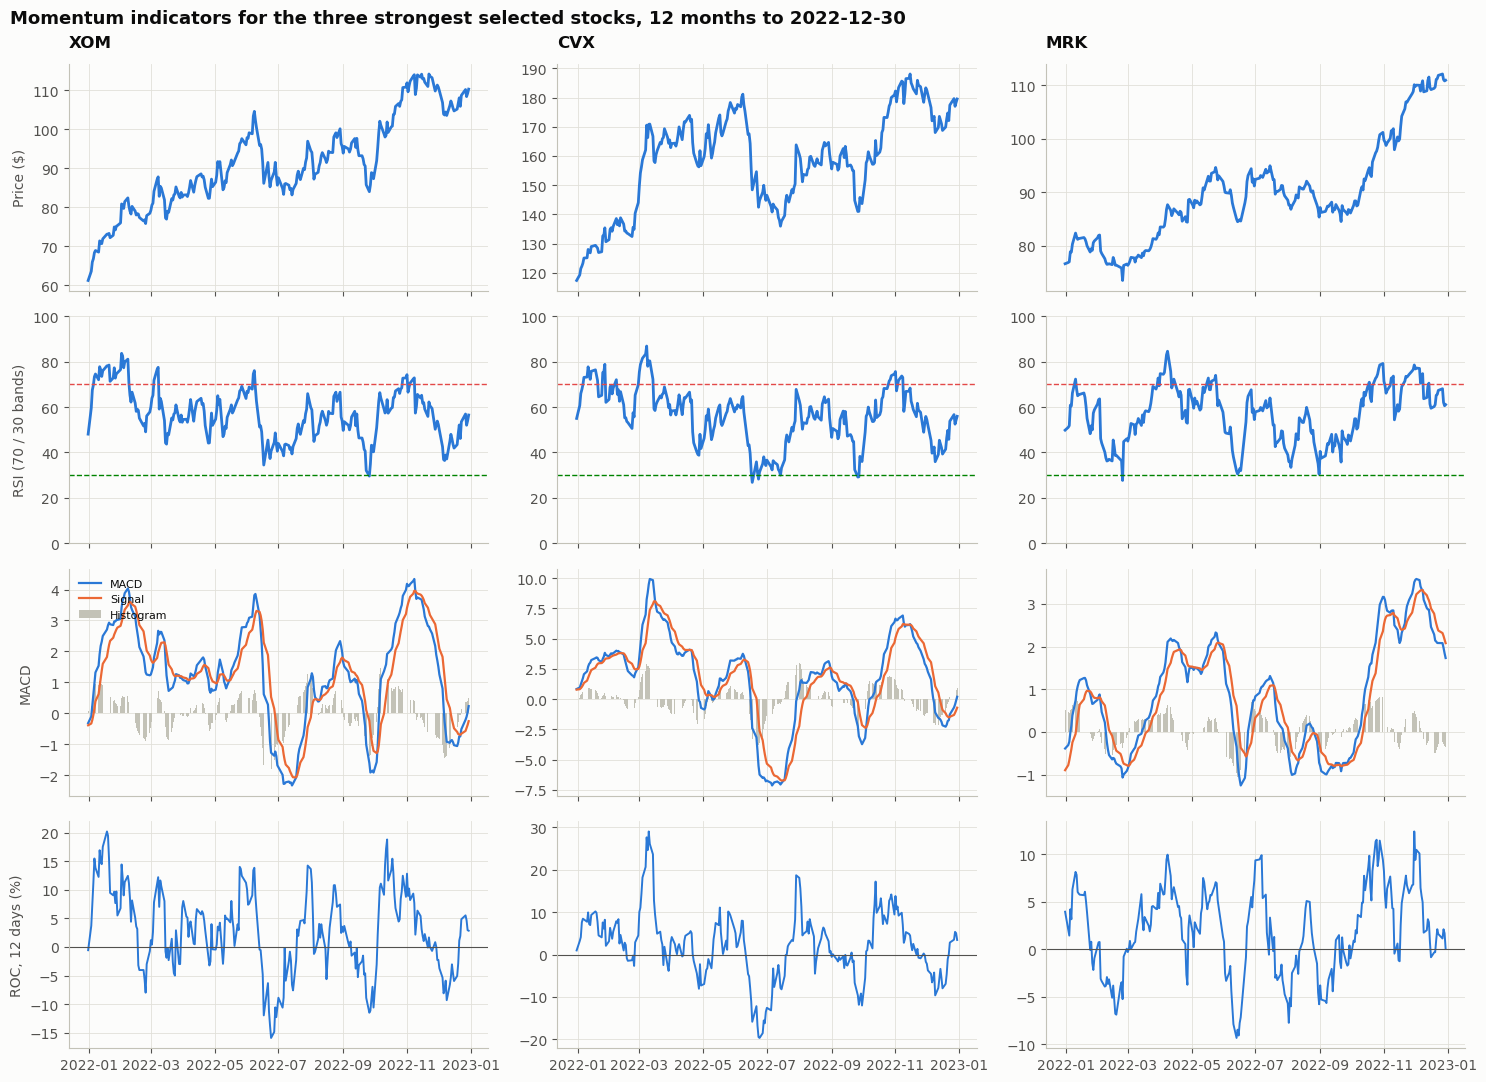

In [8]:
# Momentum indicators for the three strongest selected stocks (last 12 months to the formation date)
show = selected.index[:3]
fig, axes = plt.subplots(4, len(show), figsize=(15, 11), sharex="col")
for j, t in enumerate(show):
    s = prices.loc[:FIRST, t].dropna()
    line, signal = macd(s)
    roc = s.pct_change(12) * 100
    r = rsi(s)
    w = s.index[-MOM_LOOKBACK:]
    axes[0, j].plot(w, s[w], color=BLUE); axes[0, j].set_title(t)
    axes[1, j].plot(w, r[w], color=BLUE)
    axes[1, j].axhline(70, color=RED, ls="--", lw=1); axes[1, j].axhline(30, color=GREEN, ls="--", lw=1)
    axes[1, j].set_ylim(0, 100)
    axes[2, j].bar(w, (line - signal)[w], color=AXIS, label="Histogram")
    axes[2, j].plot(w, line[w], color=BLUE, lw=1.6, label="MACD")
    axes[2, j].plot(w, signal[w], color=ORANGE, lw=1.6, label="Signal")
    axes[3, j].plot(w, roc[w], color=BLUE, lw=1.4); axes[3, j].axhline(0, color=INK_2, lw=0.8)
for ax, label in zip(axes[:, 0], ["Price ($)", "RSI (70 / 30 bands)", "MACD", "ROC, 12 days (%)"]):
    ax.set_ylabel(label)
axes[2, 0].legend(loc="upper left", fontsize=8)
fig.suptitle(f"Momentum indicators for the three strongest selected stocks, 12 months to {FIRST.date()}",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
plt.tight_layout()
save_fig(fig, "momentum_indicators")

## 5. ARIMA return views

For each stock, `auto_arima` chooses an ARIMA order for its **quarterly log returns** up to the formation date, with no seasonal term. That order is then refitted **with an intercept forced on**: otherwise the stepwise search sometimes drops the intercept, and a (0,0,0) model forecasts exactly 0 instead of the stock's average return. The one-quarter-ahead forecast, annualised, becomes the stock's view in Black-Litterman.

Forecasts are computed for every universe stock on every rebalance date, in parallel, and cached in `cache/`, so the many backtest variants below reuse them.

In [9]:
from mts.arima import quarterly_log_returns, fit_arima, arima_views

views = pd.DataFrame({t: v for (_, t), v in arima_views([(FIRST, t) for t in selected.index]).items()}).T
views[["view_annual", "fc_quarter", "ci_low", "ci_high"]] = views[["view_annual", "fc_quarter", "ci_low", "ci_high"]].astype(float)
views

,view_annual,fc_quarter,ci_low,ci_high,order
XOM,0.0469,0.0115,-0.2310,0.2539,"(0, 0, 0)"
CVX,-0.0827,-0.0216,-0.2514,0.2082,"(1, 0, 0)"
MRK,0.0305,0.0075,-0.2127,0.2277,"(0, 0, 0)"
LLY,0.1606,0.0372,-0.1589,0.2334,"(3, 1, 1)"
TMUS,0.0498,0.0121,-0.3593,0.3835,"(0, 0, 0)"
BMY,0.0119,0.0030,-0.2283,0.2342,"(0, 0, 0)"
ABBV,-0.0472,-0.0121,-0.2241,0.2000,"(1, 0, 0)"
RTX,-0.0741,-0.0192,-0.2660,0.2275,"(0, 0, 1)"
UNH,0.2062,0.0469,-0.1981,0.2918,"(0, 0, 0)"
KO,0.0109,0.0027,-0.1511,0.1565,"(3, 0, 0)"


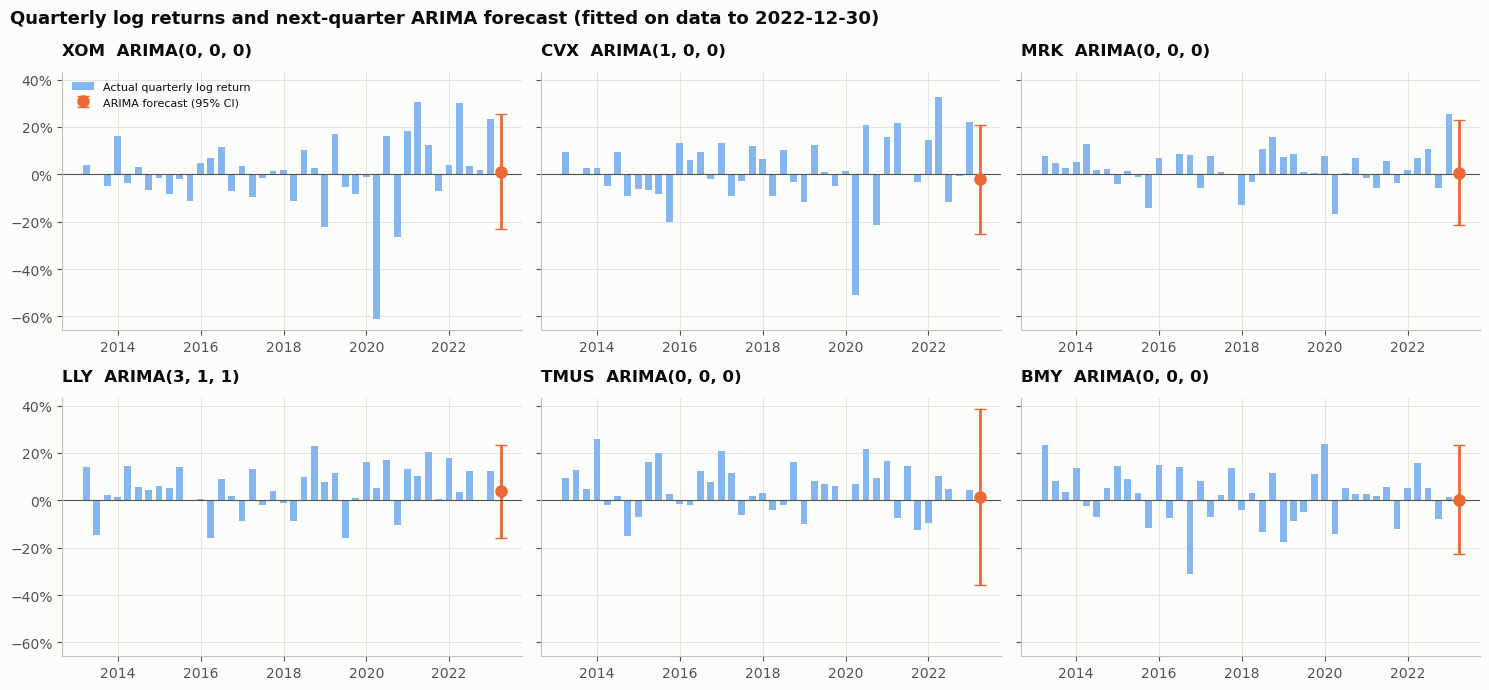

In [10]:
# History and forecast for six of the selected stocks
show = selected.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.flat, show):
    q = quarterly_log_returns(FIRST, t).iloc[-40:]
    nxt = q.index[-1] + pd.offsets.QuarterEnd()
    ax.bar(q.index, q.values, width=60, color=LIGHT_BLUE, label="Actual quarterly log return")
    v = views.loc[t]
    ax.errorbar([nxt], [v.fc_quarter], yerr=[[v.fc_quarter - v.ci_low], [v.ci_high - v.fc_quarter]],
                fmt="o", color=ORANGE, ms=8, capsize=4, label="ARIMA forecast (95% CI)")
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.set_title(f"{t}  ARIMA{v.order}")
    ax.yaxis.set_major_formatter(pct_axis)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Quarterly log returns and next-quarter ARIMA forecast (fitted on data to {FIRST.date()})",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
plt.tight_layout()
save_fig(fig, "arima_forecasts")

## 6. Black-Litterman allocation

All quantities are **annual excess returns** over the risk-free rate.

* Covariance: $\Sigma$ = covariance of 3 years of daily returns × 252, estimated with **Ledoit-Wolf shrinkage** by default. The plain sample covariance of 25 stocks is noisy, and max-Sharpe optimisation amplifies that noise.
* Risk aversion: $\delta = \text{MRP} / (w_{mkt}^\top \Sigma\, w_{mkt})$
* Prior (implied returns): $\pi = \delta\, \Sigma\, w_{mkt}$, where $w_{mkt}$ are market-cap weights
* Views: one absolute view per stock ($P = I$), $Q$ = ARIMA forecast − risk-free rate, with uncertainty $\Omega = \text{diag}(P\, \tau\Sigma\, P^\top)$ (He & Litterman)
* Posterior mean: $\mu_{BL} = \pi + \tau\Sigma P^\top (P\,\tau\Sigma\,P^\top + \Omega)^{-1}(Q - P\pi)$
* Posterior covariance: $\Sigma_{BL} = \Sigma + \left[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\right]^{-1}$
* Without views (`use_views=False`): $\mu = \pi$ and $\Sigma_{BL} = (1+\tau)\Sigma$

Weights maximise $w^\top\mu_{BL} / \sqrt{w^\top\Sigma_{BL}w}$, long-only, fully invested, each at most `max_weight`. If no stock has a positive expected excess return, the minimum-variance portfolio is used instead. Every vector stays labelled by ticker.

In [11]:
from mts.baseline import covariance, black_litterman

bl = black_litterman(FIRST, list(selected.index), uni, views["view_annual"],
                     **{k: BASE[k] for k in ("tau", "max_weight", "cov", "use_views")})
held = bl[bl["weight"] > 0.001].sort_values("weight", ascending=False)
print(f"Holding {len(held)} of {len(bl)} stocks on {FIRST.date()}")
held

Holding 6 of 25 stocks on 2022-12-30


,weight,w_mkt,prior_pi,view_Q,posterior_mu,volatility
V,0.2000,0.0604,0.0612,0.1619,0.1035,0.3363
MA,0.2000,0.0460,0.0673,0.2664,0.1237,0.3769
PG,0.2000,0.0494,0.0383,0.2640,0.0927,0.2463
UNH,0.1838,0.0682,0.0582,0.1762,0.0789,0.3322
LLY,0.1492,0.0478,0.0447,0.1306,0.0620,0.3470
COST,0.0670,0.0279,0.0368,0.0223,0.0446,0.2744


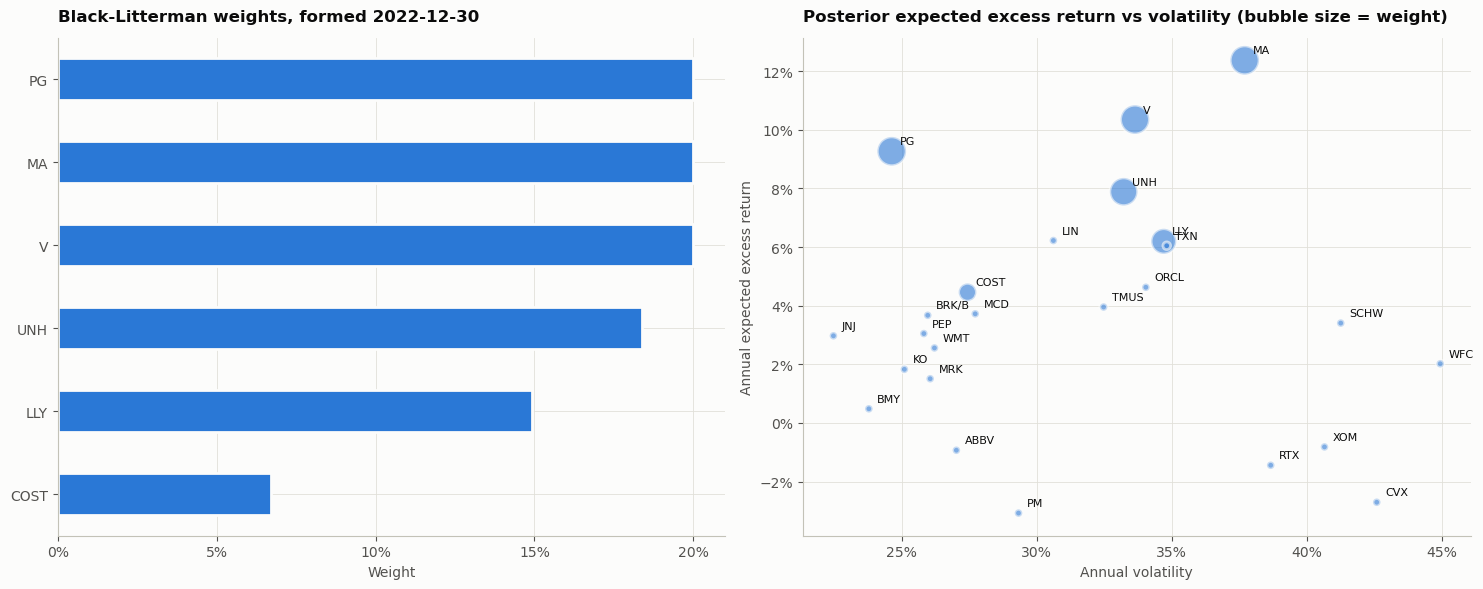

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
held["weight"].sort_values().plot(kind="barh", ax=ax1, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax1.xaxis.set_major_formatter(pct_axis)
ax1.xaxis.set_major_locator(MultipleLocator(0.05))
ax1.set_title(f"Black-Litterman weights, formed {FIRST.date()}")
ax1.set_xlabel("Weight")

ax2.scatter(bl["volatility"], bl["posterior_mu"], s=30 + bl["weight"] * 2000, color=BLUE, alpha=0.6,
            edgecolor=SURFACE, linewidth=2)
ax2.xaxis.set_major_formatter(pct_axis)
ax2.yaxis.set_major_formatter(pct_axis)
for t, row in bl.iterrows():
    ax2.annotate(t, (row["volatility"], row["posterior_mu"]), xytext=(6, 5), textcoords="offset points", fontsize=8)
ax2.set_title("Posterior expected excess return vs volatility (bubble size = weight)")
ax2.set_xlabel("Annual volatility")
ax2.set_ylabel("Annual expected excess return")
plt.tight_layout()
save_fig(fig, "black_litterman_allocation")

## 7. Backtest engine

**Precompute.** For every rebalance date from 2010 to 2023, the universe, momentum signals and ARIMA forecasts for all 50 universe stocks are computed once. Any variant of the strategy can then be backtested in seconds.

**Simulation.** On each formation date the target weights are set. Between rebalances the holdings **drift** with prices (buy-and-hold); a stock that stops trading keeps its last price.

**Costs.** At each rebalance, turnover = Σ|target weight − drifted weight|, and the portfolio pays `COST_BPS` per unit traded. The first purchase is charged too.

**Benchmarks** (same rebalancing and costs):
* **Equal-weight top 50:** the same universe, equally weighted
* **Cap-weight top 50:** the same universe, weighted by market cap
* **Cap-weight S&P 500:** all index members by market cap, a proxy for the S&P 500 price index

**Statistics.** Alongside return, volatility, Sharpe and drawdown, each portfolio is compared with the S&P 500 proxy: annual excess return, tracking error, information ratio (IR = excess return ÷ tracking error), and a t-statistic (IR × √years). A t-statistic below about 2 means the difference could easily be luck.

In [13]:
t0 = time.time()
context = {}
for f in long_dates:
    u = universe(f)
    sp = universe(f, size=10_000)
    context[f] = {"universe": u, "sp500": sp, "signals": momentum_signals(f, list(u.index))}
all_views = arima_views([(f, t) for f in long_dates for t in context[f]["signals"].index])
for f in long_dates:
    context[f]["views"] = pd.Series({t: all_views[(f, t)]["view_annual"] for t in context[f]["signals"].index})
print(f"Precomputed {len(context)} rebalance dates in {time.time() - t0:.0f}s")

Precomputed 56 rebalance dates in 3s


In [14]:
def strategy(n_select=25, rsi_max=70, max_weight=0.20, tau=0.05, cov="ledoit_wolf",
             use_views=True, weighting="black_litterman", ctx=None):
    # Returns a function: formation date -> target weights. `ctx` selects the universe (default: top 50).
    def weights(f):
        c = (ctx if ctx is not None else context)[f]
        sel = select_stocks(c["signals"], n_select, rsi_max)
        if weighting == "equal":
            return pd.Series(1 / len(sel), index=sel.index)
        bl = black_litterman(f, list(sel.index), c["universe"], c["views"],
                             tau=tau, max_weight=max_weight, cov=cov, use_views=use_views)
        return bl["weight"]
    return weights


BENCHMARKS = {
    "Equal-weight top 50": lambda f: pd.Series(1 / len(context[f]["universe"]), index=context[f]["universe"].index),
    "Cap-weight top 50": lambda f: context[f]["universe"] / context[f]["universe"].sum(),
    "Cap-weight S&P 500": lambda f: context[f]["sp500"] / context[f]["sp500"].sum(),
}


# The engine (drifting holdings, turnover, costs, no-trade bands, partial rebalancing) and the
# statistics are in mts.backtest
simulate, performance = bt.simulate, bt.performance


def show_performance(perf):
    pct = [c for c in ["CAGR", "Volatility", "Max drawdown", "Turnover / yr", "Excess vs S&P", "Tracking error"] if c in perf]
    num = [c for c in ["Sharpe", "IR", "t-stat"] if c in perf]
    return perf.style.format("{:.1%}", subset=pct).format("{:.2f}", subset=num)


def run(portfolios, dates, end):
    # Curves are kept as a dict of Series: each carries its turnover in .attrs
    sims = {name: simulate(fn, dates, end) for name, fn in portfolios.items()}
    curves = {name: s[0] for name, s in sims.items()}
    logs = {name: s[1] for name, s in sims.items()}
    return curves, logs


STRATEGY = {"Strategy": strategy(**BASE)}

## 8. Walk-forward backtest: 2023

Four rebalances, after costs.

In [15]:
curves_2023, logs_2023 = run({**STRATEGY, **BENCHMARKS}, test_dates, TEST_END)
show_performance(performance(curves_2023))

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
Strategy,11.5%,13.3%,0.66,-9.1%,453.1%,-12.0%,9.9%,-1.21,-1.21
Equal-weight top 50,23.1%,12.4%,1.50,-9.7%,56.7%,-2.2%,2.7%,-0.83,-0.83
Cap-weight top 50,37.2%,15.0%,2.00,-8.7%,12.0%,9.0%,4.5%,1.99,1.99
Cap-weight S&P 500,25.7%,13.3%,1.56,-10.0%,2.7%,0.0%,0.0%,nan,nan


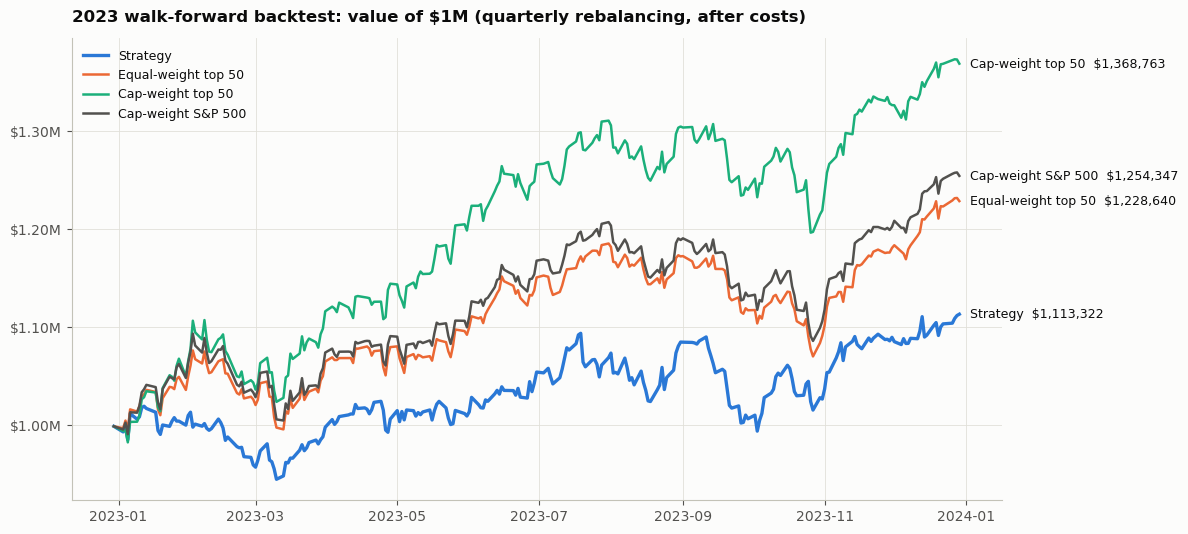

,2022-12-30,2023-03-31,2023-06-30,2023-09-29
MA,20.0%,3.7%,20.0%,6.6%
V,20.0%,2.2%,20.0%,15.4%
PG,20.0%,0.0%,0.0%,0.0%
UNH,18.4%,7.5%,0.0%,0.0%
LLY,14.9%,20.0%,0.0%,20.0%
COST,6.7%,0.0%,0.0%,0.0%
LIN,0.0%,0.0%,0.0%,0.8%
MRK,0.0%,0.0%,0.0%,20.0%
KO,0.0%,9.7%,0.0%,0.0%
TXN,0.0%,20.0%,0.0%,0.0%


In [16]:
START_VALUE = 1_000_000
NAMES = ["Strategy", "Equal-weight top 50", "Cap-weight top 50", "Cap-weight S&P 500"]
fig, ax = plt.subplots(figsize=(12, 6))
plot_lines(ax, {k: v * START_VALUE for k, v in curves_2023.items()}, NAMES, fmt="${:,.0f}")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1e6:.2f}M"))
ax.set_title("2023 walk-forward backtest: value of $1M (quarterly rebalancing, after costs)")
save_fig(fig, "backtest_2023")

alloc = logs_2023["Strategy"]
alloc = alloc.loc[(alloc > 0.001).any(axis=1)]
alloc.columns = [d.date() for d in alloc.columns]
alloc.sort_values(alloc.columns[0], ascending=False).style.format("{:.1%}")

## 9. Walk-forward backtest: 2010–2023

56 rebalances, after costs.

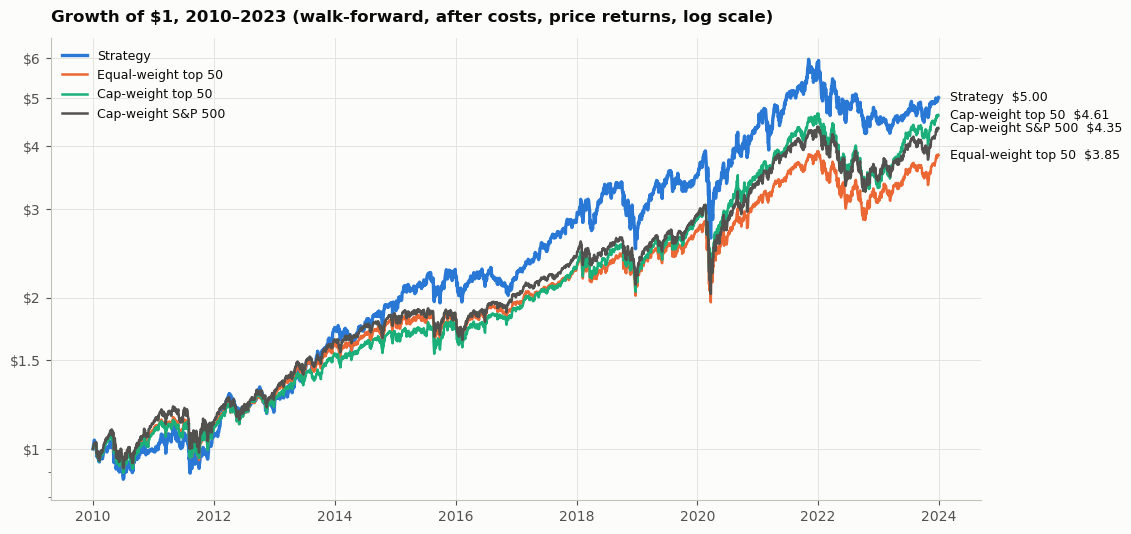

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
Strategy,12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,10.2%,0.15,0.58
Equal-weight top 50,10.1%,16.8%,0.48,-31.1%,67.1%,-1.0%,2.6%,-0.39,-1.46
Cap-weight top 50,11.5%,17.9%,0.53,-30.0%,21.9%,0.5%,3.6%,0.14,0.51
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,0.0%,nan,nan


In [17]:
curves_long, logs_long = run({**STRATEGY, **BENCHMARKS}, long_dates, LONG_END)
perf_long = performance(curves_long)

fig, ax = plt.subplots(figsize=(12, 6))
plot_lines(ax, curves_long, NAMES, fmt="${:.2f}", logy=True)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_title("Growth of $1, 2010–2023 (walk-forward, after costs, price returns, log scale)")
save_fig(fig, "equity_curve")
show_performance(perf_long)

In [18]:
yearly = pd.DataFrame(curves_long).resample(pd.offsets.YearEnd()).last().pct_change().dropna()
yearly.index = yearly.index.year
yearly["Strategy − S&P"] = yearly["Strategy"] - yearly["Cap-weight S&P 500"]
print(f"Strategy beat the S&P 500 proxy in {(yearly['Strategy − S&P'] > 0).sum()} of {len(yearly)} years")
yearly.style.format("{:.1%}")

Strategy beat the S&P 500 proxy in 8 of 14 years


,Strategy,Equal-weight top 50,Cap-weight top 50,Cap-weight S&P 500,Strategy − S&P
date,,,,,
2010,-0.8%,8.6%,7.2%,12.3%,-13.2%
2011,6.6%,0.5%,1.6%,-0.0%,6.6%
2012,14.0%,14.5%,12.9%,13.4%,0.6%
2013,44.8%,29.7%,26.0%,29.7%,15.1%
2014,10.2%,10.3%,9.1%,11.0%,-0.9%
2015,16.6%,2.1%,3.8%,0.1%,16.4%
2016,-3.0%,6.0%,7.2%,9.0%,-12.0%
2017,29.9%,17.0%,21.3%,20.1%,9.8%
2018,-3.5%,-4.5%,-3.3%,-5.9%,2.4%


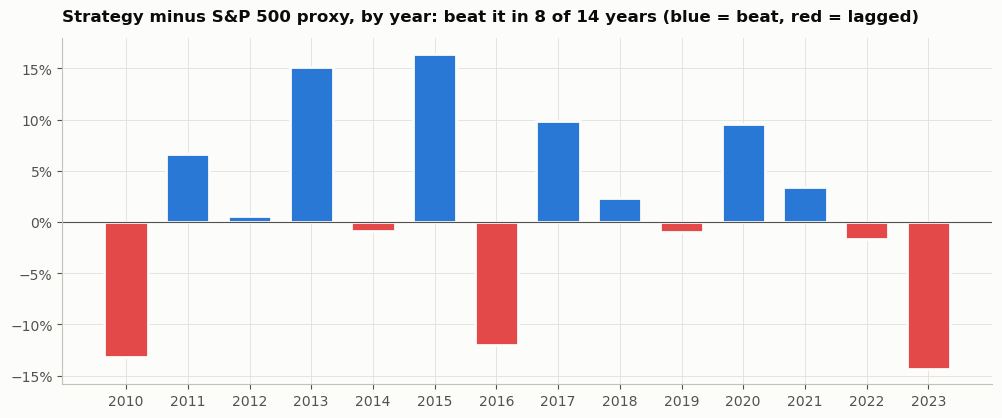

In [19]:
# Yearly excess return over the S&P 500 proxy
excess = yearly["Strategy − S&P"]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(excess.index, excess.values, color=[BLUE if v > 0 else RED for v in excess], width=0.7,
       edgecolor=SURFACE, linewidth=2)
ax.axhline(0, color=INK_2, lw=0.8)
ax.yaxis.set_major_formatter(pct_axis)
ax.set_xticks(excess.index)
ax.set_title(f"Strategy minus S&P 500 proxy, by year: beat it in {(excess > 0).sum()} of {len(excess)} years "
             "(blue = beat, red = lagged)")
save_fig(fig, "yearly_excess")

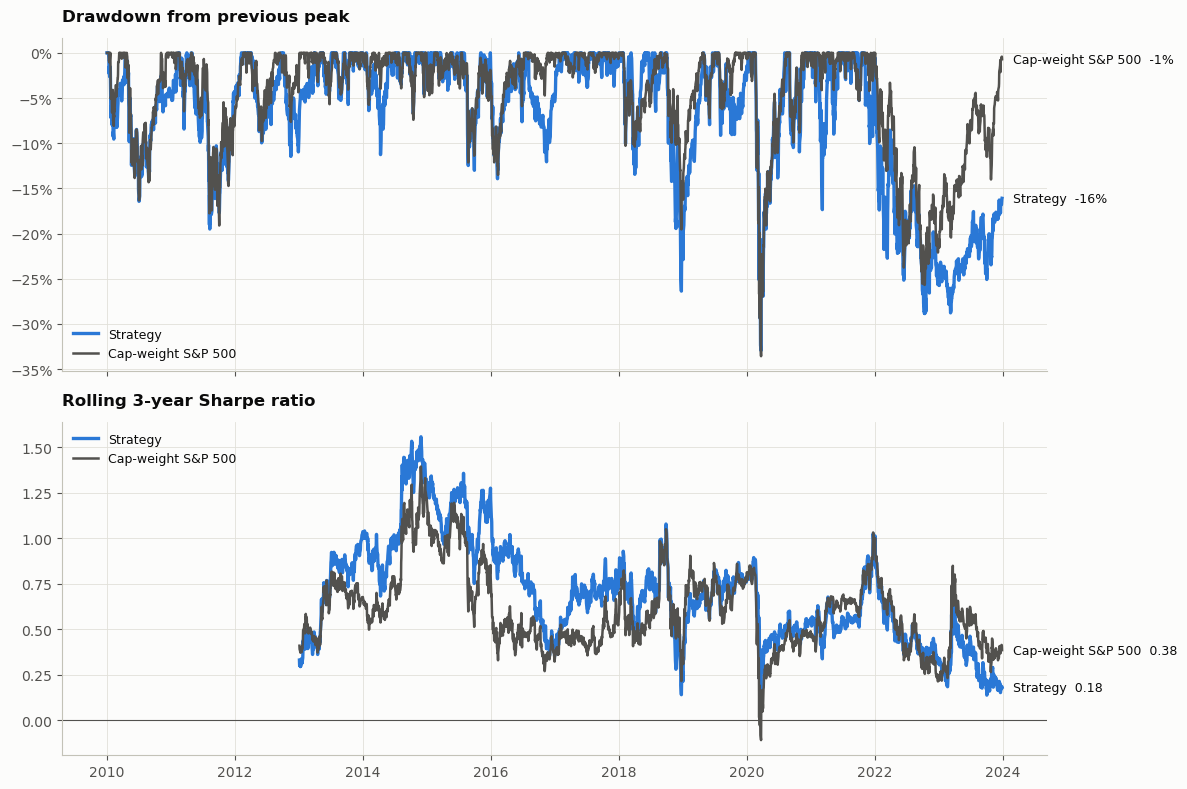

In [20]:
# Drawdowns and rolling 3-year Sharpe ratio: strategy vs the S&P 500 proxy
pair = ["Strategy", "Cap-weight S&P 500"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
drawdowns = {k: curves_long[k] / curves_long[k].cummax() - 1 for k in pair}
plot_lines(ax1, drawdowns, pair, fmt="{:.0%}", legend_loc="lower left")
ax1.yaxis.set_major_formatter(pct_axis)
ax1.set_title("Drawdown from previous peak")

rolling = {}
for k in pair:
    r = curves_long[k].pct_change()
    rolling[k] = ((r.rolling(756).mean() * 252 - RISK_FREE) / (r.rolling(756).std() * np.sqrt(252))).dropna()
plot_lines(ax2, rolling, pair, fmt="{:.2f}")
ax2.axhline(0, color=INK_2, lw=0.8)
ax2.set_title("Rolling 3-year Sharpe ratio")
plt.tight_layout()
save_fig(fig, "drawdown_rolling_sharpe")

## 10. Where does the return come from?

The strategy stacks three layers on the universe. Adding them one at a time shows which, if any, adds value:

1. **Universe, equal-weight:** the 50 largest S&P 500 stocks
2. **+ Momentum selection, equal-weight:** the top 25 by momentum, equally weighted
3. **+ Black-Litterman, no views:** the same 25 stocks, max-Sharpe on the market-implied prior only
4. **+ ARIMA views:** the full strategy

In [21]:
LAYERS = {
    "1. Universe, equal-weight": BENCHMARKS["Equal-weight top 50"],
    "2. + Momentum, equal-weight": strategy(**{**BASE, "weighting": "equal"}),
    "3. + Black-Litterman, no views": strategy(**{**BASE, "use_views": False}),
    "4. + ARIMA views (strategy)": STRATEGY["Strategy"],
    "Cap-weight S&P 500": BENCHMARKS["Cap-weight S&P 500"],
}
curves_layers, _ = run(LAYERS, long_dates, LONG_END)
perf_layers = performance(curves_layers)
show_performance(perf_layers)

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
"1. Universe, equal-weight",10.1%,16.8%,0.48,-31.1%,67.1%,-1.0%,2.6%,-0.39,-1.46
"2. + Momentum, equal-weight",10.8%,18.1%,0.49,-30.7%,259.7%,-0.2%,5.5%,-0.03,-0.11
"3. + Black-Litterman, no views",11.0%,19.1%,0.49,-30.3%,242.3%,0.2%,6.6%,0.03,0.13
4. + ARIMA views (strategy),12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,10.2%,0.15,0.58
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,0.0%,nan,nan


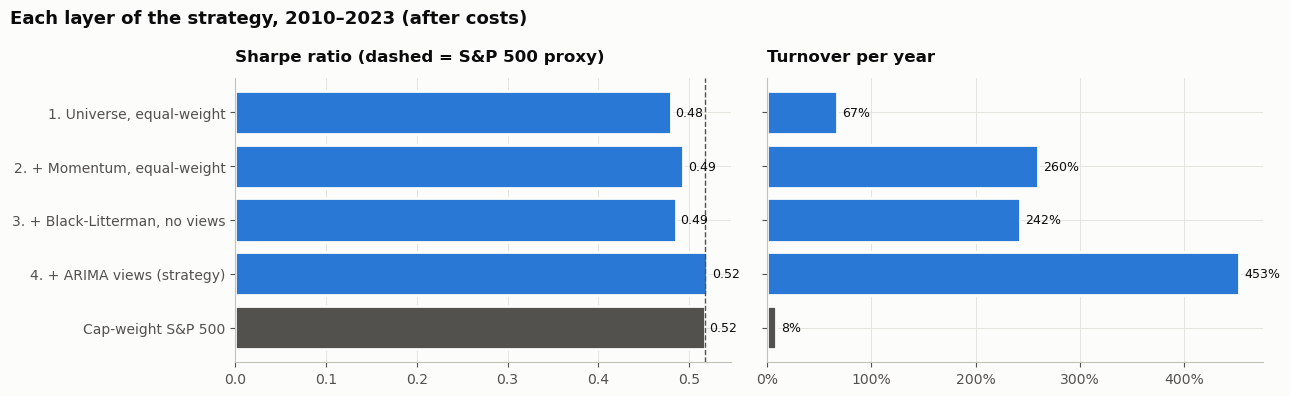

In [22]:
layers = perf_layers.iloc[::-1]
colors = [INK_2 if n == "Cap-weight S&P 500" else BLUE for n in layers.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
ax1.barh(layers.index, layers["Sharpe"], color=colors, edgecolor=SURFACE, linewidth=2)
ax1.axvline(perf_layers.loc["Cap-weight S&P 500", "Sharpe"], color=INK_2, ls="--", lw=1)
ax1.set_title("Sharpe ratio (dashed = S&P 500 proxy)")
for i, v in enumerate(layers["Sharpe"]):
    ax1.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)
ax2.barh(layers.index, layers["Turnover / yr"], color=colors, edgecolor=SURFACE, linewidth=2)
ax2.xaxis.set_major_formatter(pct_axis)
ax2.set_title("Turnover per year")
for i, v in enumerate(layers["Turnover / yr"]):
    ax2.text(v + 0.05, i, f"{v:.0%}", va="center", fontsize=9)
fig.suptitle("Each layer of the strategy, 2010–2023 (after costs)", x=0.01, ha="left",
             fontsize=13, fontweight="semibold")
plt.tight_layout()
save_fig(fig, "layers")

## 11. Sensitivity

**Settings.** Each setting is varied one at a time from the baseline, over 2010–2023 after costs. If small changes swing the result widely, the baseline result should not be trusted.

**Costs.** The baseline is re-run at 0, 25 and 50 bps per trade.

**Time.** The 14 years are split into two halves to check that the result is not driven by one period.

In [23]:
VARIANTS = {"Baseline": {}}
VARIANTS.update({f"max_weight = {v:.0%}": {"max_weight": v} for v in (0.10, 0.30, 1.00)})
VARIANTS.update({f"n_select = {v}": {"n_select": v} for v in (15, 35)})
VARIANTS.update({"No RSI filter": {"rsi_max": 101}})
VARIANTS.update({f"tau = {v}": {"tau": v} for v in (0.025, 0.10)})
VARIANTS.update({"Sample covariance": {"cov": "sample"}})

rows = {}
for name, change in VARIANTS.items():
    curve, _ = simulate(strategy(**{**BASE, **change}), long_dates, LONG_END)
    rows[name] = curve
for bps in (0, 25, 50):
    curve, _ = simulate(STRATEGY["Strategy"], long_dates, LONG_END, cost_bps=bps)
    rows[f"Cost = {bps} bps"] = curve
rows["Cap-weight S&P 500"] = curves_long["Cap-weight S&P 500"]

perf_sens = performance(rows)
show_performance(perf_sens[["CAGR", "Volatility", "Sharpe", "Max drawdown", "Turnover / yr", "Excess vs S&P", "IR", "t-stat"]])

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,IR,t-stat
Baseline,12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,0.15,0.58
max_weight = 10%,13.8%,19.6%,0.60,-32.0%,368.5%,2.8%,0.33,1.25
max_weight = 30%,11.9%,21.2%,0.50,-33.6%,494.9%,1.5%,0.13,0.48
max_weight = 100%,13.7%,24.5%,0.53,-33.8%,569.7%,3.8%,0.24,0.89
n_select = 15,14.2%,20.7%,0.60,-33.1%,421.3%,3.4%,0.32,1.19
n_select = 35,12.8%,20.1%,0.55,-36.5%,450.8%,2.1%,0.20,0.76
No RSI filter,12.0%,20.6%,0.51,-32.8%,422.7%,1.4%,0.14,0.53
tau = 0.025,12.2%,20.4%,0.52,-32.9%,453.3%,1.6%,0.15,0.57
tau = 0.1,12.2%,20.4%,0.52,-33.0%,452.9%,1.6%,0.15,0.58
Sample covariance,12.2%,20.5%,0.52,-33.0%,454.0%,1.6%,0.16,0.59


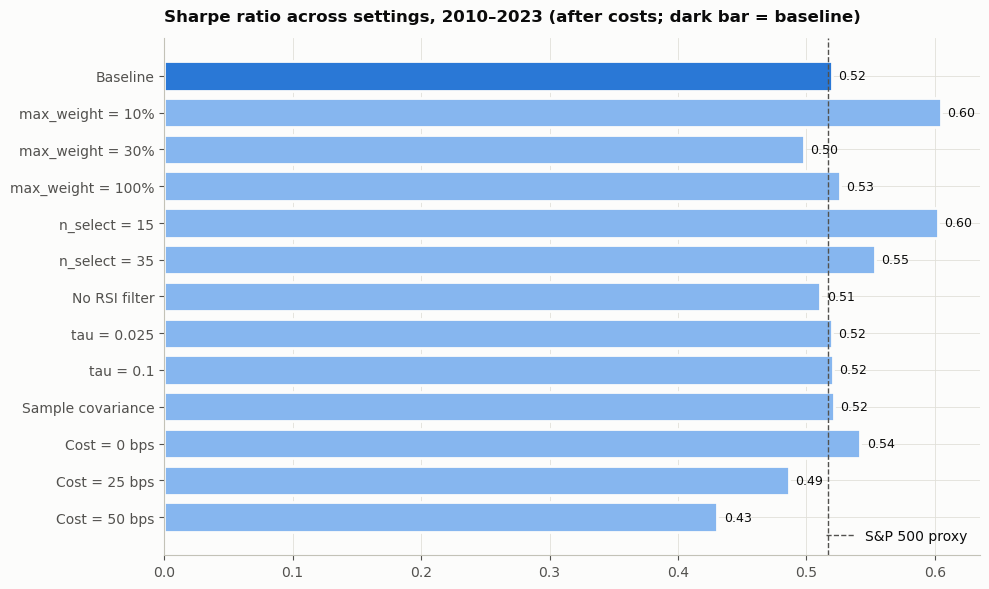

Sharpe across 13 variants: min 0.43, median 0.52, max 0.60 (S&P 500 proxy: 0.52)
Variants beating the S&P 500 proxy's Sharpe: 9 of 13


In [24]:
variants = perf_sens.drop(index="Cap-weight S&P 500")
v = variants["Sharpe"].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(v.index, v.values, color=[BLUE if n == "Baseline" else LIGHT_BLUE for n in v.index],
        edgecolor=SURFACE, linewidth=2)
ax.axvline(perf_sens.loc["Cap-weight S&P 500", "Sharpe"], color=INK_2, ls="--", lw=1, label="S&P 500 proxy")
for i, x in enumerate(v.values):
    ax.text(x + 0.005, i, f"{x:.2f}", va="center", fontsize=9)
ax.set_title("Sharpe ratio across settings, 2010–2023 (after costs; dark bar = baseline)")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig(fig, "sensitivity")

print(f"Sharpe across {len(variants)} variants: min {variants['Sharpe'].min():.2f}, "
      f"median {variants['Sharpe'].median():.2f}, max {variants['Sharpe'].max():.2f} "
      f"(S&P 500 proxy: {perf_sens.loc['Cap-weight S&P 500', 'Sharpe']:.2f})")
print(f"Variants beating the S&P 500 proxy's Sharpe: {(variants['Sharpe'] > perf_sens.loc['Cap-weight S&P 500', 'Sharpe']).sum()} of {len(variants)}")

In [25]:
halves = {}
for label, (a, b) in {"2010–2016": ("2009-12-31", "2016-12-31"), "2017–2023": ("2016-12-30", "2023-12-31")}.items():
    sliced = {}
    for k, v in curves_long.items():
        s = v.loc[a:b]
        s = s / s.iloc[0]
        s.attrs = v.attrs
        sliced[k] = s
    p = performance(sliced)[["CAGR", "Volatility", "Sharpe", "Max drawdown", "IR"]]
    p.index = pd.MultiIndex.from_product([[label], p.index])
    halves[label] = p
pd.concat(halves.values()).style.format("{:.1%}", subset=["CAGR", "Volatility", "Max drawdown"]).format("{:.2f}", subset=["Sharpe", "IR"])

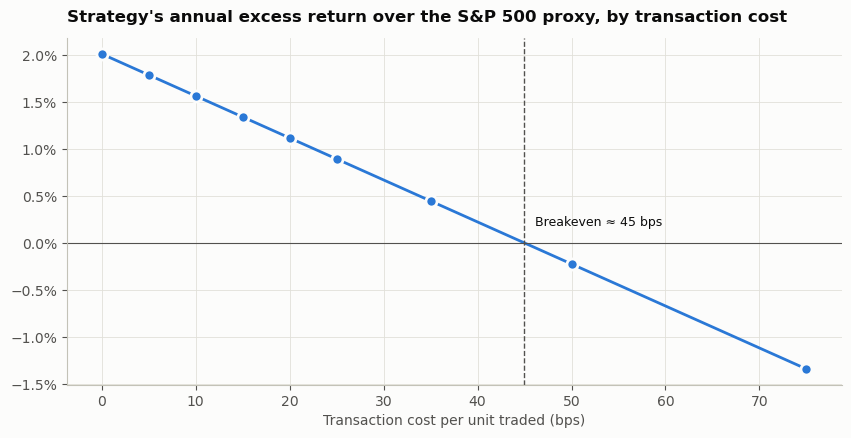

Breakeven cost: 45 bps


,Excess vs S&P
0,2.01%
5,1.79%
10,1.56%
15,1.34%
20,1.11%
25,0.89%
35,0.44%
50,-0.23%
75,-1.34%


In [26]:
# Cost breakeven: strategy and S&P 500 proxy both pay the same cost per trade
cost_levels = [0, 5, 10, 15, 20, 25, 35, 50, 75]
edge = {}
for bps in cost_levels:
    strat, _ = simulate(STRATEGY["Strategy"], long_dates, LONG_END, cost_bps=bps)
    bench, _ = simulate(BENCHMARKS["Cap-weight S&P 500"], long_dates, LONG_END, cost_bps=bps)
    edge[bps] = performance({"Strategy": strat, "Cap-weight S&P 500": bench}).loc["Strategy", "Excess vs S&P"]
edge = pd.Series(edge)
breakeven = np.interp(0, edge.values[::-1], edge.index.values[::-1])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(edge.index, edge.values, color=BLUE, marker="o", ms=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axhline(0, color=INK_2, lw=0.8)
ax.axvline(breakeven, color=INK_2, ls="--", lw=1)
ax.annotate(f"Breakeven ≈ {breakeven:.0f} bps", xy=(breakeven, 0), xytext=(8, 12),
            textcoords="offset points", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Transaction cost per unit traded (bps)")
ax.set_title("Strategy's annual excess return over the S&P 500 proxy, by transaction cost")
save_fig(fig, "cost_breakeven")
print(f"Breakeven cost: {breakeven:.0f} bps")
edge.to_frame("Excess vs S&P").style.format("{:.2%}")

## 12. Full S&P 500 universe

Everything above uses the 50 largest stocks. Momentum is usually studied across the whole market, and academic evidence suggests it is weaker among the largest, most-watched stocks. Here the same pipeline selects from **all ~500 index members** on each date (still point-in-time from the snapshots):

* **Strategy (full S&P 500):** the top 25 by momentum (RSI < 70), with ARIMA views and Black-Litterman, exactly as before
* **Momentum equal-weight (full S&P 500):** the classic momentum portfolio, the top 50 (the top decile) by 12-1 momentum, equally weighted, with no RSI filter, ARIMA or optimiser
* **Equal-weight S&P 500:** the fair benchmark for an equal-weighted portfolio, since equal-weighting alone tilts towards smaller companies

In [27]:
t0 = time.time()
context_full = {}
for f in long_dates:
    sp = context[f]["sp500"]
    context_full[f] = {"universe": sp, "sp500": sp, "signals": momentum_signals(f, list(sp.index))}
print(f"Momentum signals for ~500 stocks x {len(long_dates)} dates in {time.time() - t0:.0f}s")

jobs = [(f, t) for f in long_dates
        for t in select_stocks(context_full[f]["signals"], BASE["n_select"], BASE["rsi_max"]).index]
full_views = arima_views(jobs)
for f in long_dates:
    picks = [t for ff, t in jobs if ff == f]
    context_full[f]["views"] = pd.Series({t: full_views[(f, t)]["view_annual"] for t in picks})

UNIVERSE_TESTS = {
    "Strategy": STRATEGY["Strategy"],
    "Strategy (full S&P 500)": strategy(**BASE, ctx=context_full),
    "Momentum equal-weight (full S&P 500)": strategy(**{**BASE, "n_select": 50, "rsi_max": 101, "weighting": "equal"},
                                                     ctx=context_full),
    "Equal-weight S&P 500": lambda f: pd.Series(1 / len(context[f]["sp500"]), index=context[f]["sp500"].index),
    "Cap-weight S&P 500": BENCHMARKS["Cap-weight S&P 500"],
}
curves_full, logs_full = run(UNIVERSE_TESTS, long_dates, LONG_END)
perf_full = performance(curves_full)
show_performance(perf_full)

Momentum signals for ~500 stocks x 56 dates in 16s


,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
Strategy,12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,10.2%,0.15,0.58
Strategy (full S&P 500),7.3%,25.0%,0.29,-45.5%,603.4%,-1.9%,16.2%,-0.12,-0.44
Momentum equal-weight (full S&P 500),8.2%,21.8%,0.33,-38.2%,405.8%,-1.8%,10.0%,-0.18,-0.66
Equal-weight S&P 500,10.4%,18.6%,0.47,-39.1%,43.0%,-0.4%,5.1%,-0.08,-0.29
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,0.0%,nan,nan


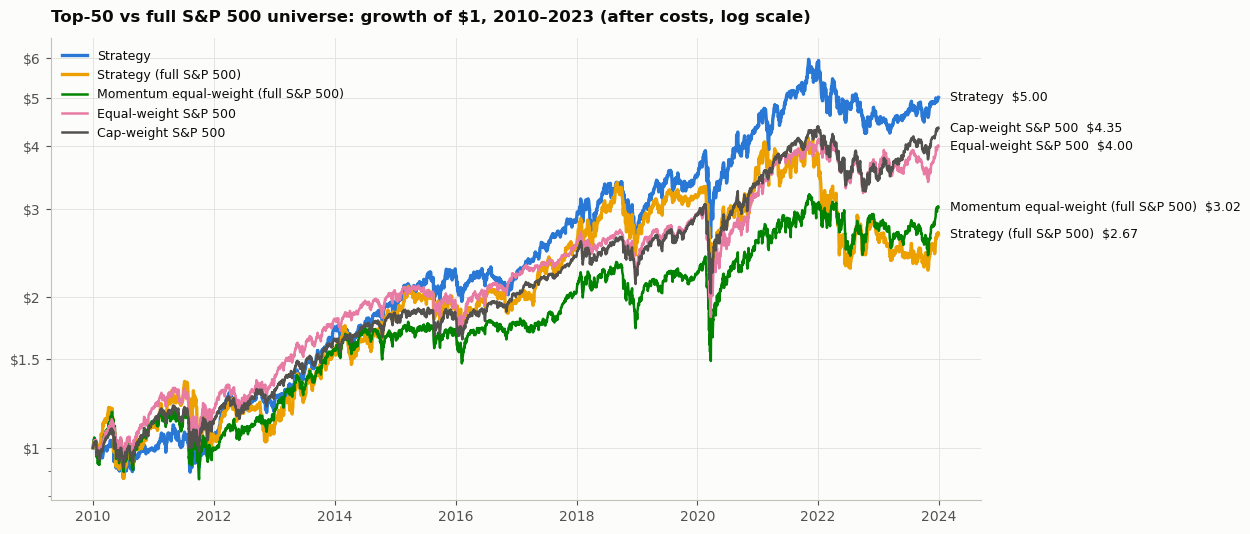

,2010–2016,2017–2023
Strategy,0.58,0.50
Strategy (full S&P 500),0.40,0.19
Momentum equal-weight (full S&P 500),0.35,0.32
Equal-weight S&P 500,0.57,0.38
Cap-weight S&P 500,0.53,0.52


In [28]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_lines(ax, curves_full, list(UNIVERSE_TESTS), fmt="${:.2f}", logy=True)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_title("Top-50 vs full S&P 500 universe: growth of $1, 2010–2023 (after costs, log scale)")
save_fig(fig, "universe_comparison")

full_halves = {}
for label, (a, b) in {"2010–2016": ("2009-12-31", "2016-12-31"), "2017–2023": ("2016-12-30", "2023-12-31")}.items():
    sliced = {k: (v.loc[a:b] / v.loc[a:b].iloc[0]) for k, v in curves_full.items()}
    full_halves[label] = performance(sliced)["Sharpe"]
pd.DataFrame(full_halves).style.format("{:.2f}")

## 13. Reducing turnover

The baseline strategy trades about 450% of its value a year. Two standard ways to trade less, applied on top of the same target weights:

* **No-trade band:** skip any trade smaller than the band (for example, don't rebalance a stock whose weight is within 2 percentage points of target)
* **Partial rebalancing:** move only part of the way (for example 50%) from the current weights toward the target each quarter

Each variant is compared at 10 bps, and at 25 bps where lower turnover matters more.

In [29]:
TURNOVER_VARIANTS = {
    "Baseline": {},
    "No-trade band 2%": {"band": 0.02},
    "No-trade band 5%": {"band": 0.05},
    "Partial rebalance 50%": {"adjust": 0.5},
    "Band 2% + partial 50%": {"band": 0.02, "adjust": 0.5},
}
rows = {}
for bps in (10, 25):
    curves = {name: simulate(STRATEGY["Strategy"], long_dates, LONG_END, cost_bps=bps, **kw)[0]
              for name, kw in TURNOVER_VARIANTS.items()}
    curves["Cap-weight S&P 500"] = simulate(BENCHMARKS["Cap-weight S&P 500"], long_dates, LONG_END, cost_bps=bps)[0]
    p = performance(curves)[["CAGR", "Volatility", "Sharpe", "Turnover / yr", "Excess vs S&P", "IR", "t-stat"]]
    p.index = pd.MultiIndex.from_product([[f"{bps} bps"], p.index])
    rows[bps] = p
perf_turnover = pd.concat(rows.values())
show_performance(perf_turnover)

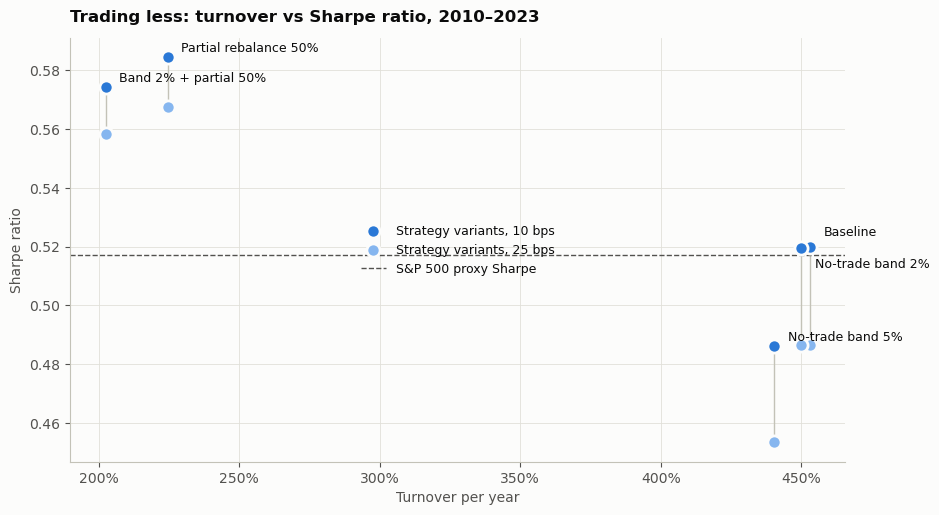

In [30]:
p10 = perf_turnover.loc["10 bps"]
p25 = perf_turnover.loc["25 bps"]
strat = [n for n in p10.index if n != "Cap-weight S&P 500"]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(p10.loc[strat, "Turnover / yr"], p10.loc[strat, "Sharpe"], s=90, color=BLUE,
           edgecolor=SURFACE, linewidth=2, label="Strategy variants, 10 bps", zorder=3)
ax.scatter(p25.loc[strat, "Turnover / yr"], p25.loc[strat, "Sharpe"], s=90, color=LIGHT_BLUE,
           edgecolor=SURFACE, linewidth=2, label="Strategy variants, 25 bps", zorder=3)
offsets = {"Baseline": (10, 8), "No-trade band 2%": (10, -14)}
for n in strat:
    x = p10.loc[n, "Turnover / yr"]
    ax.plot([x, x], [p10.loc[n, "Sharpe"], p25.loc[n, "Sharpe"]], color=AXIS, lw=1, zorder=1)
    ax.annotate(n, (x, p10.loc[n, "Sharpe"]), xytext=offsets.get(n, (10, 4)),
                textcoords="offset points", fontsize=9)
ax.axhline(p10.loc["Cap-weight S&P 500", "Sharpe"], color=INK_2, ls="--", lw=1, label="S&P 500 proxy Sharpe")
ax.xaxis.set_major_formatter(pct_axis)
ax.set_xlabel("Turnover per year")
ax.set_ylabel("Sharpe ratio")
ax.set_title("Trading less: turnover vs Sharpe ratio, 2010–2023")
ax.legend(loc="center", fontsize=9)
save_fig(fig, "turnover_tradeoff")

## 14. Findings

All figures are after 10 bps transaction costs and exclude dividends.

**1. There is no statistically meaningful edge.** Over 2010–2023 the strategy returned 12.2% a year against 11.1% for the S&P 500 proxy, but with more risk (20.4% vs 17.5% volatility). The Sharpe ratio is the same (0.52 vs 0.52), the information ratio is 0.15, and the t-statistic is **0.58**, far below the ~2 needed to rule out luck. The strategy beat the S&P proxy in 8 of 14 years.

**2. The layers add risk, not risk-adjusted return** (section 10):

| Layer | Sharpe | Turnover / yr |
|---|---|---|
| Universe, equal-weight | 0.48 | 67% |
| + Momentum selection | 0.49 | 260% |
| + Black-Litterman (no views) | 0.49 | 242% |
| + ARIMA views | 0.52 | 453% |

**3. The results are stable, and consistently unremarkable** (section 11). Across 13 variants the Sharpe ranges from 0.43 to 0.60, against 0.52 for the S&P proxy, and the best t-statistic is about 1.2. τ has no effect, because with the He-Litterman choice $\Omega = \text{diag}(P\,\tau\Sigma\,P^\top)$ it cancels out of the posterior mean. Ledoit-Wolf vs sample covariance makes no difference, because the weight cap already limits how far the optimiser can chase noise.

**4. Costs matter.** The excess return falls from 2.0% a year at 0 bps to zero at about **45 bps**.

**5. Both halves agree.** Sharpe 0.58 vs 0.53 for the S&P proxy in 2010–2016, and 0.50 vs 0.52 in 2017–2023.

**6. A wider universe makes momentum worse, not better** (section 12). Selecting from all ~500 members gave a Sharpe of 0.29 for the strategy and 0.33 for classic top-decile momentum, against 0.47 for equal-weight S&P 500 and 0.52 for cap-weight. Momentum was a weak factor among US large caps in this period, and the wider universe adds more volatile stocks (maximum drawdown −45%).

**7. Trading less helps; no-trade bands don't** (section 13). Moving only 50% of the way to the target each quarter halves turnover (453% → 225%) and raises the Sharpe from 0.52 to 0.58 (t-statistic 1.15). No-trade bands barely reduce turnover (5% band: 441%), because most trades are whole-position swaps (0% ↔ 20%) that are far larger than any band. Partial rebalancing is the most promising change, but it was found after testing several variants, so it would need confirming on fresh data before being trusted.

**8. 2023 was a bad year for the strategy:** 11.5% against 25.7% for the S&P proxy. Momentum at the end of 2022 pointed towards energy and defensive stocks, while 2023 was led by mega-cap tech.

**Limitations**
* **Price returns only.** The dataset's dividend field is empty. Absolute returns are understated for every portfolio by roughly the dividend yield (about 2% a year for the S&P 500). The effect on the *comparison* depends on yield differences this data cannot show.
* **Special dividends look like crashes.** For example KDP shows −82% on 2018-07-10, the Keurig–Dr Pepper merger's $103 special dividend. Such artifacts affect every portfolio holding the stock, the equal-weight benchmarks included.
* **Simple cost model.** Costs are linear, with no market impact or bid-ask detail.